<h1>Creación de Modelos Predictivos</h1>

<h2>Importar las Librerías Necesarias</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

<h2>Modelos de Clasificación</h2>

In [2]:
dataset = fetch_ucirepo(id=468)
df_clasificacion = pd.concat([dataset.data.features, dataset.data.targets], axis=1)

<h3>Análisis de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>
<b>Consideraciones de Análisis de Calidad</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos son consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas no tengan errores ortográficos o de estilo.</li>
</ul>

In [3]:
print("Cantidad de valores vacios en cada columna:")
df_clasificacion.isna().sum()

Cantidad de valores vacios en cada columna:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [44]:
print("Tipos de datos de cada columna y valores no nulos:")
df_clasificacion.info()

Tipos de datos de cada columna y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-n

In [13]:
print("Valores Encontrados en VisorType")
print(df_clasificacion["VisitorType"].unique())

print("Valores Encontrados en Month")
print(df_clasificacion["Month"].unique())

Valores Encontrados en VisorType
<StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str
Valores Encontrados en Month
<StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str


<Axes: xlabel='Month', ylabel='Count'>

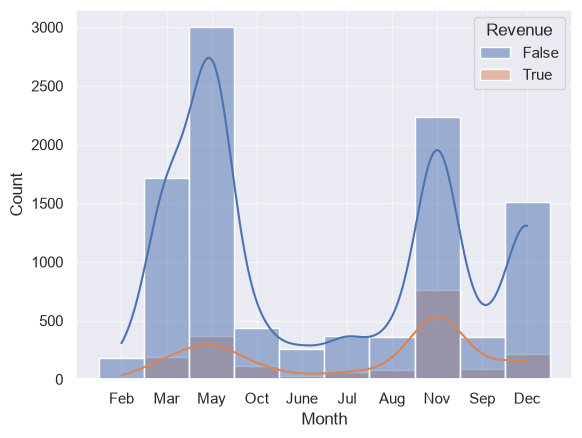

In [26]:
sns.set_theme()
sns.histplot(data=df_clasificacion,x="Month", hue="Revenue", bins=15, kde=True)

<Axes: xlabel='VisitorType', ylabel='Revenue'>

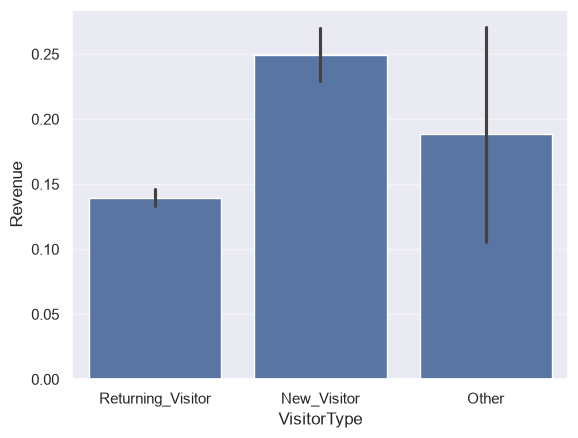

In [33]:
sns.barplot(data=df_clasificacion, x="VisitorType", y="Revenue")

<h3>Fundamentación del Modelo</h3>

In [4]:
X_clasificacion = df_clasificacion.drop(columns='Revenue')
y_clasificacion = df_clasificacion['Revenue'].astype(int)

In [5]:
X_trainclass, X_testclass, y_trainclass, y_testclass = train_test_split(X_clasificacion, y_clasificacion, test_size=0.2, random_state=42, stratify=y_clasificacion)